# Meshtastic metadata in SME logistics: calculations, visualisations, conclusions

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/omega2417/bnt/blob/claude/modest-mayer-c9rmmz/meshtastic_logistics_collector/notebooks/meshtastic_logistics_analysis.ipynb)

Companion notebook to the software package **Meshtastic Logistics Metadata Collector** (v1.0.0) and the article
*Strengthening Economic Autonomy in SME Logistics with Meshtastic Mesh Networks*.
It follows the whole chain from a radio frame to the indicators used in the article:

| # | Section | What is calculated |
|---|---|---|
| 1 | Logistics frame protocol | layout of the 24-byte frame, CRC protection |
| 2 | LoRa airtime | time-on-air of the frame vs JSON, message limits from duty cycle and the *U* = 25 % limit |
| 3 | Synthetic data and the collector | replay log generation, storage in SQLite |
| 4 | L1 — radio metadata | packet types, flood duplicates, hops, SNR/RSSI |
| 5 | L2 — device state | channel utilisation *U*, relay airtime |
| 6 | Positions: delivery and AoI | delivery ratio *p*, age of information; check against an analytic formula and Monte Carlo |
| 7 | L3 — logistics events | life cycle, *η* (Equation 9), *A*ₒₚ, *R*ₗₒₛₛ |
| 8 | KPIs and sensitivity | comparison with the reference output, *A*ₒₚ as a function of the deadline |
| 9 | Link to the economic model | *R*ₗₒₛₛ vs the break-even threshold *q*\* = 35.4 % |
| 10 | Conclusions | |

> ⚠️ **All data here are synthetic** (3 vehicles, 6 h, ≈15 % lost positions). The numbers illustrate the method
> and test the code; they are **not field measurements**.

## 0. Environment setup

Nothing has to be installed in Colab: `pandas`, `numpy` and `matplotlib` are preinstalled, and the package itself
uses only the Python standard library (`meshtastic` is needed only for a live radio).

The cell below looks for the package code in this order:
1. next to the notebook (opened from the repository or from the unpacked archive);
2. a direct ZIP link (`ZIP_URL`, e.g. the file of the Zenodo record);
3. a clone of the GitHub repository (`REPO_URL`, works if the repository is public);
4. in Colab, a prompt to upload the ZIP manually (`meshtastic_logistics_collector-v1.0.0.zip`).

In [1]:
# --- Locate or download the package code ------------------------------------------------
import os, sys, glob, json, shutil, sqlite3, subprocess, tempfile, zipfile, urllib.request
from pathlib import Path

ZIP_URL = ""   # after the Zenodo deposit: direct link to the ZIP file of the record
REPO_URL = "https://github.com/omega2417/bnt.git"
BRANCH = "claude/modest-mayer-c9rmmz"
IN_COLAB = "google.colab" in sys.modules

def find_pkg():
    """Return the directory that contains logi_proto.py, or None."""
    here = Path.cwd()
    cands = [here, here.parent, *here.glob("meshtastic_logistics_collector*"),
             *Path("/content").glob("meshtastic_logistics_collector*"),
             Path("/content/bnt/meshtastic_logistics_collector"), here / "bnt/meshtastic_logistics_collector"]
    for c in cands:
        if (c / "logi_proto.py").exists():
            return c.resolve()
    return None

def unzip_here(zpath):
    with zipfile.ZipFile(zpath) as z:
        z.extractall(Path.cwd())

PKG = find_pkg()
if PKG is None and ZIP_URL:
    urllib.request.urlretrieve(ZIP_URL, "mlc.zip"); unzip_here("mlc.zip"); PKG = find_pkg()
if PKG is None:
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", BRANCH, REPO_URL, str(Path.cwd() / "bnt")],
                   capture_output=True, text=True)
    PKG = find_pkg()
if PKG is None and IN_COLAB:
    from google.colab import files
    print("Upload meshtastic_logistics_collector-v1.0.0.zip")
    for name in files.upload():
        unzip_here(name)
    PKG = find_pkg()
assert PKG is not None, "Package code not found: put the notebook next to the package or set ZIP_URL"

sys.path.insert(0, str(PKG))
WORK = Path(tempfile.mkdtemp(prefix="mlc_"))   # packets.jsonl, ops.json and test.db are written here
print("Package:", PKG)
print("Working directory:", WORK)

Package: /home/user/bnt/meshtastic_logistics_collector
Working directory: /tmp/mlc_d_8u5s44


In [2]:
# --- Libraries, package modules, plot style ---------------------------------------------
import math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import logi_proto as lp
from kpi import kpis

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)

T0, T1 = 1_800_000_000, 1_800_021_600     # window of the synthetic run: 6 hours
C = dict(ok="#2a9d8f", warn="#e9c46a", bad="#e76f51", base="#264653", grey="#9aa5ab")

def run(script, *args):
    """Run a package script exactly as from the command line (as in the README)."""
    r = subprocess.run([sys.executable, str(PKG / script), *map(str, args)], cwd=WORK, text=True,
                       capture_output=True, env={**os.environ, "PYTHONPATH": str(PKG)})
    if r.returncode:
        raise RuntimeError(r.stderr)
    return r.stdout.strip()

## 1. Logistics frame protocol

A logistics event (temperature excursion, delay, cargo handover, …) is sent not as text but as a
**fixed-length 24-byte binary frame** on port `PRIVATE_APP` (256). The same `event_id` is reused by the
ACCEPT / DONE replies, so the gateway can reconstruct the full life cycle of each event.

Below we encode the event "temperature excursion +8.5 °C, deadline 30 min" and decode the frame field by field.

Frame length: 24 bytes;  hex: 01 01 a1 b2 c3 d4 e5 f6 00 00 01 f5 01 03 6b 49 d2 64 00 55 00 1e 36 fd


,field,bytes,size,value,hex
0,version,0–0,1,1,01
1,msg_type,1–1,1,1 = EVENT,01
2,event_id,2–7,6,a1b2c3d4e5f6,a1b2c3d4e5f6
3,operation_id,8–11,4,501,000001f5
4,event_code,12–12,1,1 = TEMP_EXCURSION,01
5,priority,13–13,1,3,03
6,t_created,14–17,4,1800000100,6b49d264
7,value,18–19,2,85 (= 8.5 °C),0055
8,deadline_min,20–21,2,30,001e
9,crc16,22–23,2,36fd,36fd


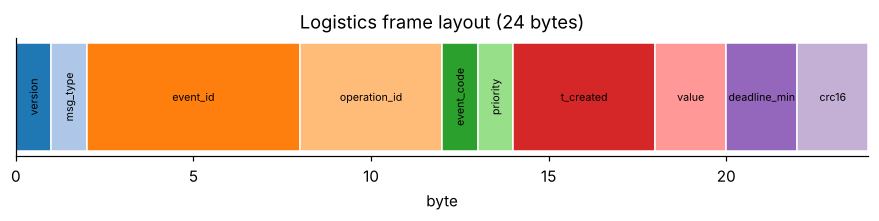

In [3]:
ev = lp.LogiMsg(msg_type=1, event_id=bytes.fromhex("a1b2c3d4e5f6"), operation_id=501,
                event_code=1, priority=3, t_created=T0 + 100, value=85, deadline_min=30)
raw = ev.encode()
print(f"Frame length: {len(raw)} bytes;  hex: {raw.hex(' ')}")

# Field layout: name, size in bytes, value
fields = [("version", 1, ev.version), ("msg_type", 1, f"{ev.msg_type} = {lp.MSG_TYPES[ev.msg_type]}"),
          ("event_id", 6, ev.event_hex), ("operation_id", 4, ev.operation_id),
          ("event_code", 1, f"{ev.event_code} = {lp.EVENT_CODES[ev.event_code]}"),
          ("priority", 1, ev.priority), ("t_created", 4, ev.t_created),
          ("value", 2, f"{ev.value} (= {ev.value/10:.1f} °C)"), ("deadline_min", 2, ev.deadline_min),
          ("crc16", 2, raw[-2:].hex())]
off = np.cumsum([0] + [f[1] for f in fields])
frame = pd.DataFrame({"field": [f[0] for f in fields], "bytes": [f"{a}–{b-1}" for a, b in zip(off, off[1:])],
                      "size": [f[1] for f in fields], "value": [f[2] for f in fields],
                      "hex": [raw[a:b].hex() for a, b in zip(off, off[1:])]})
display(frame)

fig, ax = plt.subplots(figsize=(10, 1.4))
for (name, size, _), start, col in zip(fields, off, plt.cm.tab20.colors):
    ax.barh(0, size, left=start, color=col, edgecolor="white")
    ax.text(start + size / 2, 0, name, ha="center", va="center", fontsize=7, rotation=90 if size < 2 else 0)
ax.set_xlim(0, 24); ax.set_yticks([]); ax.set_xlabel("byte"); ax.grid(False)
ax.set_title("Logistics frame layout (24 bytes)")
plt.show()

**Corruption protection.** Meshtastic channel encryption does not guarantee that business logic receives a valid
frame (another protocol version, a truncated packet, a firmware bug). The frame therefore carries a CRC-16/CCITT,
and the collector drops anything that fails the check. Let us flip one bit and truncate the frame.

In [4]:
bad = bytearray(raw); bad[10] ^= 0x01
for label, data in [("valid", raw), ("one bit flipped", bytes(bad)), ("truncated by 1 byte", raw[:-1])]:
    try:
        lp.LogiMsg.decode(data); print(f"{label:22s} → accepted")
    except ValueError as e:
        print(f"{label:22s} → rejected ({e})")

valid                  → accepted
one bit flipped        → rejected (crc mismatch)
truncated by 1 byte    → rejected (bad length 23)


## 2. LoRa airtime: why a binary frame and not JSON

LoRa airtime is a shared and slow resource. Every millisecond of transmission consumes the node's duty-cycle budget
(e.g. 1 % per hour in the 868 MHz band) and raises the channel utilisation *U*, which drives collisions.
Packet time-on-air follows the Semtech formula (AN1200.13):

$$T_{sym}=\frac{2^{SF}}{BW},\qquad
n_{payload}=8+\max\!\left(\left\lceil\frac{8PL-4SF+28+16-20H}{4(SF-2DE)}\right\rceil(CR+4),\,0\right),$$
$$T_{air}=(n_{preamble}+4.25)\,T_{sym}+n_{payload}\,T_{sym},$$

where *PL* is the LoRa payload length in bytes, *CR* = 1…4 for 4/5…4/8, *H* = 0 (explicit header) and
*DE* = 1 if $T_{sym}$ > 16 ms. Meshtastic uses a 16-symbol preamble and adds a 16-byte header plus a protobuf
wrapper (≈5 bytes for port 256) to the application data. Preset parameters are taken from the Meshtastic
documentation; the result is an **estimate**, not a measurement.

In [5]:
PRESETS = {  # name: (SF, BW in Hz, CR: 1 = 4/5 … 4 = 4/8)
    "SHORT_FAST": (7, 250e3, 1), "SHORT_SLOW": (8, 250e3, 1), "MEDIUM_FAST": (9, 250e3, 1),
    "MEDIUM_SLOW": (10, 250e3, 1), "LONG_FAST": (11, 250e3, 1), "LONG_MODERATE": (11, 125e3, 4),
    "LONG_SLOW": (12, 125e3, 4)}
MESH_OVERHEAD = 16 + 5        # Meshtastic header + protobuf Data wrapper (estimate)

def time_on_air(app_bytes, sf, bw, cr, preamble=16):
    pl = app_bytes + MESH_OVERHEAD
    tsym = 2 ** sf / bw
    de = 1 if tsym > 0.016 else 0
    n = 8 + max(math.ceil((8 * pl - 4 * sf + 28 + 16) / (4 * (sf - 2 * de))) * (cr + 4), 0)
    return (preamble + 4.25) * tsym + n * tsym

# The same content as JSON, the "obvious" alternative to a binary frame
as_json = json.dumps({"v": 1, "type": "EVENT", "event_id": ev.event_hex, "op": ev.operation_id,
                      "code": "TEMP_EXCURSION", "prio": 3, "t": ev.t_created, "value": 8.5,
                      "deadline_min": 30}, separators=(",", ":"))
print(f"Binary frame: {len(raw)} bytes; JSON: {len(as_json)} bytes ({len(as_json)/len(raw):.1f}×)")

toa = pd.DataFrame([{"preset": p, "24-byte frame, ms": 1e3 * time_on_air(len(raw), *v),
                     "JSON, ms": 1e3 * time_on_air(len(as_json), *v)} for p, v in PRESETS.items()]).set_index("preset")
toa["gain, ×"] = toa["JSON, ms"] / toa["24-byte frame, ms"]
display(toa.round(1))

Binary frame: 24 bytes; JSON: 135 bytes (5.6×)


,"24-byte frame, ms","JSON, ms","gain, ×"
preset,,,
SHORT_FAST,50.3,132.2,2.6
SHORT_SLOW,90.4,233.7,2.6
MEDIUM_FAST,170.5,416.3,2.4
MEDIUM_SLOW,320.5,771.1,2.4
LONG_FAST,600.1,1419.3,2.4
LONG_MODERATE,1773.6,5050.4,2.8
LONG_SLOW,3285.0,9314.3,2.8


**How many events fit?** Two limits apply:
* *node duty cycle*: at 1 % per hour a node has 36 s of airtime;
* *channel utilisation*: keeping *U* ≤ 25 % (the level above which Meshtastic starts throttling transmissions)
  leaves 900 s of airtime per hour for the whole channel. Every event is rebroadcast, so its airtime is multiplied
  by the number of copies (original + rebroadcasts). We assume 3 copies.

,events/h per node (1 %),events/h in network (U ≤ 25 %),same for JSON
preset,,,
SHORT_FAST,716,5964,2269
SHORT_SLOW,398,3320,1284
MEDIUM_FAST,211,1760,721
MEDIUM_SLOW,112,936,389
LONG_FAST,60,500,211
LONG_MODERATE,20,169,59
LONG_SLOW,11,91,32


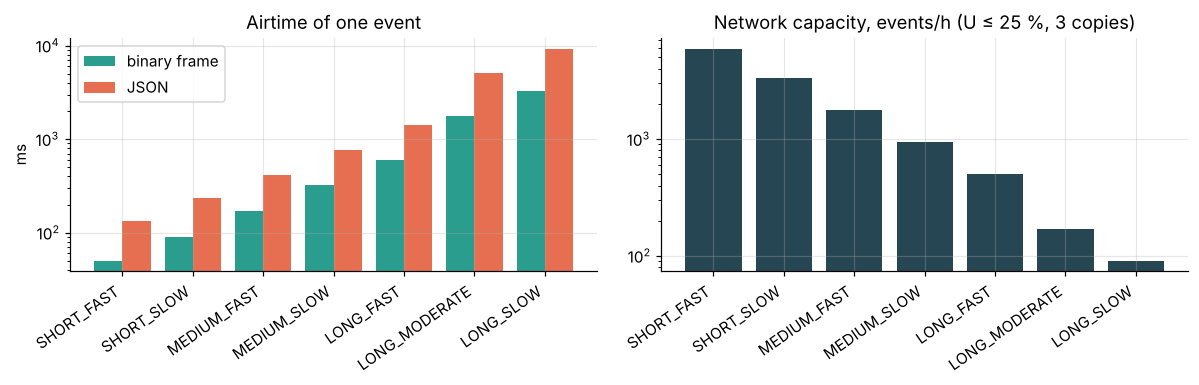

In [6]:
DUTY, U_MAX, COPIES = 0.01, 0.25, 3
cap = pd.DataFrame({
    "events/h per node (1 %)": 3600 * DUTY / (toa["24-byte frame, ms"] / 1e3),
    "events/h in network (U ≤ 25 %)": 3600 * U_MAX / (COPIES * toa["24-byte frame, ms"] / 1e3),
    "same for JSON": 3600 * U_MAX / (COPIES * toa["JSON, ms"] / 1e3)}).round(0).astype(int)
display(cap)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(toa))
ax[0].bar(x - .2, toa["24-byte frame, ms"], .4, label="binary frame", color=C["ok"])
ax[0].bar(x + .2, toa["JSON, ms"], .4, label="JSON", color=C["bad"])
ax[0].set_xticks(x, toa.index, rotation=35, ha="right"); ax[0].set_ylabel("ms"); ax[0].set_yscale("log")
ax[0].set_title("Airtime of one event"); ax[0].legend()
ax[1].bar(x, cap["events/h in network (U ≤ 25 %)"], color=C["base"])
ax[1].set_xticks(x, cap.index, rotation=35, ha="right"); ax[1].set_yscale("log")
ax[1].set_title("Network capacity, events/h (U ≤ 25 %, 3 copies)")
plt.tight_layout(); plt.show()

**Section conclusion.** JSON with the same content is 5.6 times longer and, because of the fixed header and preamble,
takes 2.4–2.8 times more airtime (600 ms vs 1.4 s on LONG_FAST). On LONG_FAST the network carries ≈ 500 critical
events per hour, and ≈ 90 on the slowest LONG_SLOW preset, while a six-vehicle fleet generates a few to a few
dozen. **Channel capacity is not the bottleneck**: coverage and power are, which matches the article. The compact
frame still leaves headroom for positions and telemetry and lowers the collision probability.

## 3. Synthetic data and the collector

`make_replay.py` generates a packet log as if it had been received by the gateway:
* 3 vehicles (nodes 11, 12, 13) report a position every 10 min for 6 h; ≈15 % of positions are lost and
  ≈30 % of the delivered ones have a flood copy;
* relay 21 sends telemetry;
* vehicle 11 creates 4 critical events with a 30-min deadline: two are completed on time, one **late** and one
  **never**. The dispatcher (node 1) accepts all four.

Then `collector.py --replay` writes the log to SQLite, and `import_plan.py` adds the plan of critical operations
(the denominator of *A*ₒₚ) with an expected loss of 1000 UAH per operation.

In [7]:
print("packets in the log:", run("make_replay.py"))
run("collector.py", "--replay", "packets.jsonl", "--db", "test.db")
print(run("import_plan.py", "--db", "test.db", "--plan", "ops.json", "--loss", 1000))

db = sqlite3.connect(WORK / "test.db")
sql = lambda q, *p: pd.read_sql_query(q, db, params=p)
tables = ["rx_packet", "node_metric", "position", "node_registry", "logi_event", "logi_event_log",
          "planned_operation", "outage", "sync_outbox"]
display(pd.DataFrame({"rows": [db.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in tables]}, index=tables))

packets in the log: 128
4 operations imported


,rows
rx_packet,128
node_metric,1
position,89
node_registry,5
logi_event,4
logi_event_log,11
planned_operation,4
outage,0
sync_outbox,11


The `outage` table is empty: no outage windows are defined in the synthetic scenario. In a pilot it is filled
manually or from monitoring, which yields the "service loss and recovery" profile.

## 4. L1 — packet radio metadata

Every received packet is stored in `rx_packet` with the gateway time, SNR/RSSI, hop count and a duplicate flag.
A **duplicate** is another copy of the same packet (same `from` + `id` within 10 min) rebroadcast by a different
node. Duplicates are not deliveries; they measure the flooding overhead.

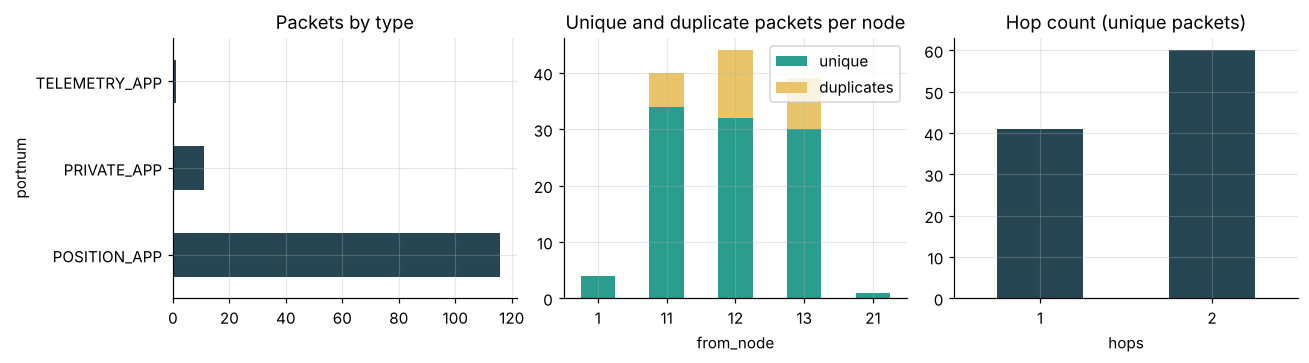

Unique packets: 101, duplicates: 27, flood overhead: 0.267 copies per packet; mean hops: 1.47


In [8]:
rx = sql("SELECT * FROM rx_packet")
rx["t_h"] = (rx.gw_rx_ts - T0) / 3600

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
rx.portnum.value_counts().plot.barh(ax=ax[0], color=C["base"]); ax[0].set_title("Packets by type")
d = rx.groupby("from_node").is_duplicate.agg(unique=lambda s: (s == 0).sum(), duplicates="sum")
d.plot.bar(stacked=True, ax=ax[1], color=[C["ok"], C["warn"]], rot=0); ax[1].set_title("Unique and duplicate packets per node")
rx[rx.is_duplicate == 0].hops_taken.value_counts().sort_index().plot.bar(ax=ax[2], color=C["base"], rot=0)
ax[2].set_title("Hop count (unique packets)"); ax[2].set_xlabel("hops")
plt.tight_layout(); plt.show()

uniq = (rx.is_duplicate == 0).sum()
print(f"Unique packets: {uniq}, duplicates: {rx.is_duplicate.sum()}, "
      f"flood overhead: {rx.is_duplicate.sum()/uniq:.3f} copies per packet; mean hops: {rx.hops_taken.mean():.2f}")

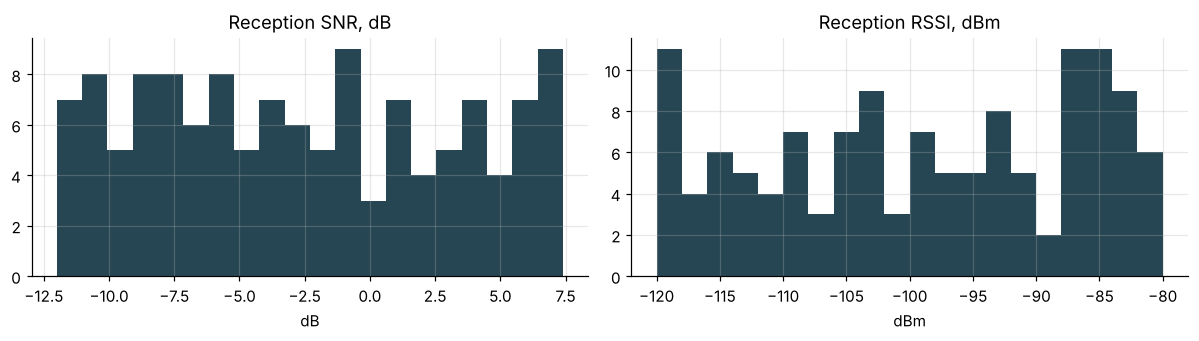

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(rx.rx_snr, bins=20, color=C["base"]); ax[0].set_title("Reception SNR, dB"); ax[0].set_xlabel("dB")
ax[1].hist(rx.rx_rssi, bins=20, color=C["base"]); ax[1].set_title("Reception RSSI, dBm"); ax[1].set_xlabel("dBm")
plt.tight_layout(); plt.show()

**Comment.** In the synthetic data SNR and RSSI are uniformly distributed, so the histograms say nothing about
coverage. In a pilot these fields, combined with positions, produce a **route coverage map**: segments with low
SNR or no reception show where a relay is needed.

## 5. L2 — device state and channel utilisation

Nodes report `channelUtilization` (share of time the channel is busy, as seen by the node) and `airUtilTx`
(own airtime over the last hour). This is a direct measurement of *U* from the article's model. We compare it with
two limits: 25 % for the channel and 1 % for the transmitter duty cycle (where the region imposes it).

,node,gw_rx_ts,battery_pct,voltage,channel_util,air_util_tx,uptime_s,temperature
0,21,1.800000e+09,87,4.01,4.2,1.3,3600,None


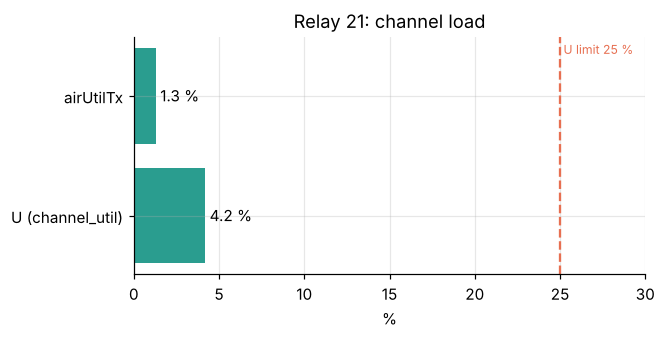

In [10]:
nm = sql("SELECT * FROM node_metric")
display(nm)
fig, ax = plt.subplots(figsize=(6, 2.8))
vals = [nm.channel_util.max(), nm.air_util_tx.max()]
ax.barh(["U (channel_util)", "airUtilTx"], vals, color=C["ok"])
ax.axvline(25, color=C["bad"], ls="--"); ax.text(25, 1.35, " U limit 25 %", color=C["bad"], fontsize=8)
for i, v in enumerate(vals):
    ax.text(v, i, f" {v:.1f} %", va="center")
ax.set_xlim(0, 30); ax.set_xlabel("%"); ax.set_title("Relay 21: channel load")
plt.show()

**Comment.** *U* = 4.2 % is six times below the 25 % limit, so capacity has a large margin (see Section 2).
`airUtilTx` = 1.3 % is already above 1 %. Where a 1 % duty cycle applies, the relay may throttle its transmissions
from time to time, so this field belongs on the dispatcher dashboard.

## 6. Positions: delivery ratio *p* and age of information (AoI)

Vehicles should report every *T* = 600 s. The delivery ratio is
$p = \min\left(\dfrac{N_{received}}{(t_1-t_0)/T},\,1\right)$.

The **age of information** shows how old the last known position is. It drops to zero at each reception and then
grows linearly (a sawtooth). The time-average AoI is the area under the sawtooth divided by the duration:
$$\overline{\Delta}=\frac{1}{t_n-t_1}\sum_{i}\frac{(t_{i+1}-t_i)^2}{2}.$$

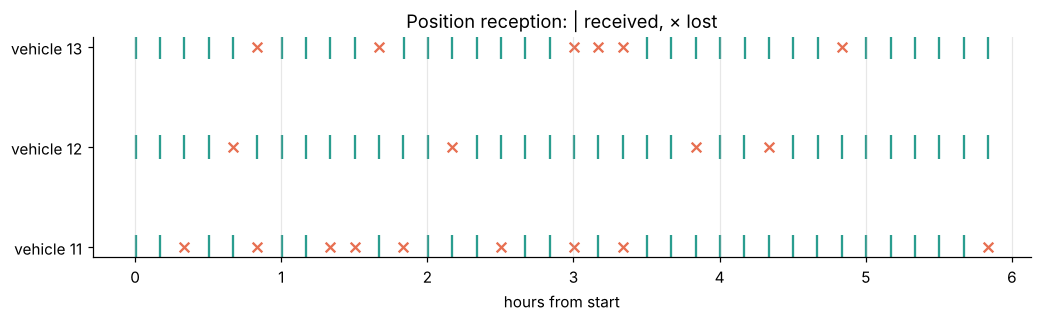

In [11]:
pos = sql("SELECT node, gw_rx_ts FROM position ORDER BY node, gw_rx_ts")
T = 600
fig, ax = plt.subplots(figsize=(11, 2.6))
for i, (n, g) in enumerate(pos.groupby("node")):
    slots = np.arange(36) * T + n                       # scheduled report times
    got = np.isin(T0 + slots, g.gw_rx_ts.values)
    ax.scatter(slots[got] / 3600, [i] * got.sum(), marker="|", s=250, color=C["ok"])
    ax.scatter(slots[~got] / 3600, [i] * (~got).sum(), marker="x", s=40, color=C["bad"])
ax.set_yticks(range(3), [f"vehicle {n}" for n in pos.node.unique()]); ax.set_xlabel("hours from start")
ax.set_title("Position reception: | received, × lost"); ax.grid(axis="y", visible=False)
plt.show()

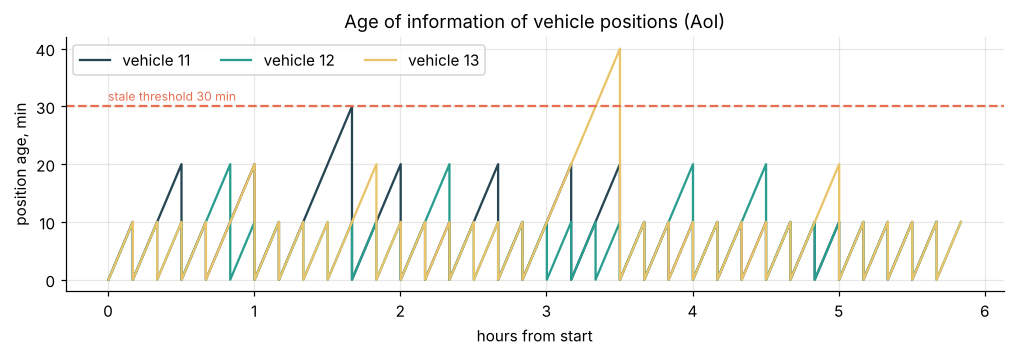

,received,expected,p,"AoI, min (manual)","max AoI, min"
node,,,,,
11,27,36.0,0.750,7.65,30.0
12,32,36.0,0.889,6.14,20.0
13,30,36.0,0.833,7.57,40.0


In [12]:
def aoi_curve(ts):
    """Sawtooth AoI points (minutes) for reception times ts."""
    x, y = [], []
    for a, b in zip(ts, ts[1:]):
        x += [a, b]; y += [0, (b - a) / 60]
    return np.array(x), np.array(y)

def aoi_mean(ts):
    ts = np.asarray(ts)
    return ((np.diff(ts) ** 2) / 2).sum() / (ts[-1] - ts[0]) / 60

res = []
fig, ax = plt.subplots(figsize=(11, 3))
for (n, g), col in zip(pos.groupby("node"), [C["base"], C["ok"], C["warn"]]):
    ts = g.gw_rx_ts.values
    x, y = aoi_curve(ts); ax.plot((x - T0) / 3600, y, color=col, label=f"vehicle {n}")
    res.append({"node": n, "received": len(ts), "expected": (T1 - T0) / T,
                "p": round(min(len(ts) / ((T1 - T0) / T), 1), 3), "AoI, min (manual)": round(aoi_mean(ts), 2),
                "max AoI, min": round(np.diff(ts).max() / 60, 1)})
ax.axhline(30, color=C["bad"], ls="--"); ax.text(0, 31, "stale threshold 30 min", color=C["bad"], fontsize=8)
ax.set_ylabel("position age, min"); ax.set_xlabel("hours from start"); ax.legend(ncol=3)
ax.set_title("Age of information of vehicle positions (AoI)"); plt.show()

aoi_df = pd.DataFrame(res).set_index("node"); display(aoi_df)

### Check against an analytic model

If reports are sent with period *T* and each one is lost independently with probability *q*, the gap between
receptions is $G = kT$, where *k* is geometric: $E[k]=\frac{1}{1-q}$, $E[k^2]=\frac{1+q}{(1-q)^2}$.
The mean AoI is
$$\overline{\Delta}=\frac{E[G^2]}{2E[G]}=\frac{T}{2}\cdot\frac{1+q}{1-q}.$$
For *q* = 0 this gives *T*/2 = 5 min. We verify the formula with Monte Carlo and add the measured (synthetic)
points using $\hat q = 1 - p$.

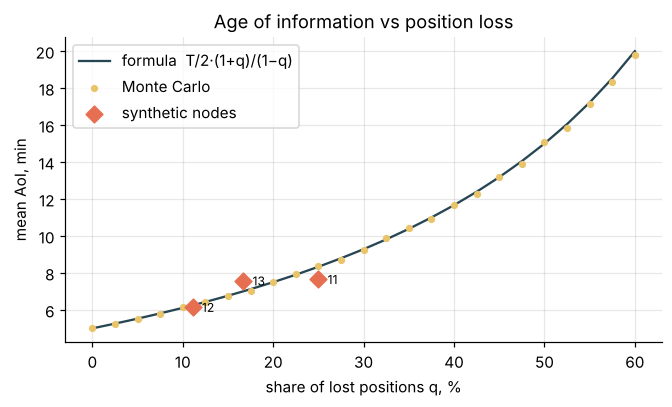

,received,expected,p,"AoI, min (manual)","max AoI, min","AoI, min (formula)"
node,,,,,,
11,27,36.0,0.750,7.65,30.0,8.33
12,32,36.0,0.889,6.14,20.0,6.25
13,30,36.0,0.833,7.57,40.0,7.00


In [13]:
rng = np.random.default_rng(0)
qs = np.linspace(0, .6, 25)
analytic = T / 2 * (1 + qs) / (1 - qs) / 60
def mc(q, n=20000):
    ok = rng.random(n) > q
    ts = np.flatnonzero(ok) * T
    return aoi_mean(ts)
sim = [mc(q) for q in qs]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(qs * 100, analytic, color=C["base"], label="formula  T/2·(1+q)/(1−q)")
ax.scatter(qs * 100, sim, s=14, color=C["warn"], label="Monte Carlo", zorder=3)
q_hat = 1 - aoi_df["p"]
ax.scatter(q_hat * 100, aoi_df["AoI, min (manual)"], s=60, color=C["bad"], marker="D", label="synthetic nodes", zorder=4)
for n, qq, a in zip(aoi_df.index, q_hat, aoi_df["AoI, min (manual)"]):
    ax.annotate(str(n), (qq * 100, a), textcoords="offset points", xytext=(6, -3), fontsize=8)
ax.set_xlabel("share of lost positions q, %"); ax.set_ylabel("mean AoI, min")
ax.set_title("Age of information vs position loss"); ax.legend(); plt.show()

aoi_df["AoI, min (formula)"] = (T / 2 * (1 + q_hat) / (1 - q_hat) / 60).round(2)
display(aoi_df)

**Comment.** Monte Carlo falls on the formula, so the formula can be used for planning. The synthetic nodes
deviate from the curve by less than 1 min: 6 hours contain only 36 reports, and the result depends on whether
losses come in a row. Practical conclusion: **AoI grows non-linearly**. At 15 % loss it is ≈ 6.8 min, at 50 % it
is 15 min, and the 30-min stale threshold is crossed by **loss bursts**, not by the average loss rate. In the
sawtooth plot vehicle 13 lost three reports in a row around hour 3 and its position aged to 40 min, although its
overall *p* = 0.83. At the same time `kpi.py` returns an empty `stale_nodes` list because it checks the age only at
the end of the window. The dispatcher dashboard therefore needs the current position age, and reports need the
maximum AoI over the window, not just the average delivery ratio.

## 7. L3 — life cycle of logistics events

**Receiving a packet ≠ completing the operation.** The collector therefore stores the creation, gateway reception,
dispatcher acceptance and completion times separately, together with the deadline. Only `DONE` **before** the
deadline counts as success.

In [14]:
ev_df = sql("""SELECT e.event_id, e.operation_id, e.status, e.t_created, e.t_rx_gw, e.t_accept, e.t_done,
                      e.deadline_ts, p.due_ts, p.loss_if_failed_uah
               FROM logi_event e LEFT JOIN planned_operation p USING(operation_id) ORDER BY e.t_rx_gw""")
rel = lambda c: ((ev_df[c] - ev_df.t_created) / 60).round(1)
view = pd.DataFrame({"operation": ev_df.operation_id, "status": ev_df.status,
                     "received, min": rel("t_rx_gw"), "accepted, min": rel("t_accept"),
                     "done, min": rel("t_done"), "deadline, min": rel("deadline_ts")})
view["on time"] = (ev_df.status == "DONE") & (ev_df.t_done <= ev_df.deadline_ts)
display(view)

,operation,status,"received, min","accepted, min","done, min","deadline, min",on time
0,501,DONE,0.0,1.0,13.3,30.0,True
1,502,DONE,0.0,1.0,13.3,30.0,True
2,503,DONE,0.0,1.0,40.0,30.0,False
3,504,ACCEPTED,0.0,1.0,NaN,30.0,False


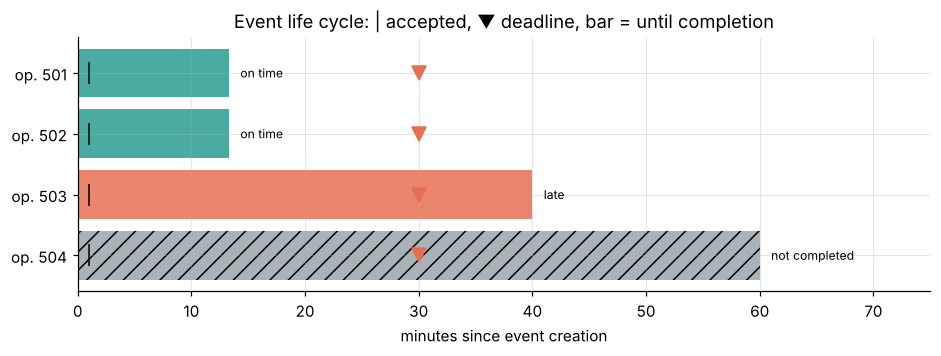

In [15]:
fig, ax = plt.subplots(figsize=(10, 3))
for i, r in view.iterrows():
    end = r["done, min"] if not np.isnan(r["done, min"]) else 60
    col = C["ok"] if r["on time"] else (C["bad"] if r["status"] == "DONE" else C["grey"])
    ax.barh(i, end, color=col, alpha=.85, hatch=None if r["status"] == "DONE" else "//")
    ax.plot(r["accepted, min"], i, "k|", ms=14)
    ax.plot(r["deadline, min"], i, marker="v", color=C["bad"], ms=9)
    lbl = "on time" if r["on time"] else ("late" if r["status"] == "DONE" else "not completed")
    ax.text(end + 1, i, lbl, va="center", fontsize=8)
ax.set_yticks(range(len(view)), [f"op. {o}" for o in view["operation"]]); ax.invert_yaxis()
ax.set_xlabel("minutes since event creation"); ax.set_xlim(0, 75)
ax.set_title("Event life cycle: | accepted, ▼ deadline, bar = until completion")
plt.show()

### Manual calculation of the indicators

* **Actionability** (Equation 9 of the article): $\eta = \dfrac{\text{events completed before the deadline}}{\text{delivered critical events}}$.
* **Operational autonomy**: $A_{op} = \dfrac{\text{planned critical operations completed before the deadline}}{\text{all planned critical operations}}$.
  The denominator comes from the plan, not from the network, so an operation whose message never arrived still stays in it.
* **Loss reduction**: $R_{loss} = \dfrac{\sum L_i\ \text{of saved operations}}{\sum L_i\ \text{of all planned operations}}$.

In [16]:
on_time = view["on time"]
eta = on_time.sum() / len(view)
ok_plan = (ev_df.status == "DONE") & (ev_df.t_done <= ev_df.due_ts)
A_op = ok_plan.sum() / len(ev_df)
R_loss = ev_df.loss_if_failed_uah[ok_plan].sum() / ev_df.loss_if_failed_uah.sum()
accept = ev_df.t_accept.notna().mean()
print(f"accepted by dispatcher: {accept:.0%}   η = {on_time.sum()}/{len(view)} = {eta:.2f}   "
      f"A_op = {A_op:.2f}   R_loss = {R_loss:.2f}")

accepted by dispatcher: 100%   η = 2/4 = 0.50   A_op = 0.50   R_loss = 0.50


**Comment.** The dispatcher accepted **100 %** of events, but only **50 %** were completed on time. The article
names this gap between "message delivered" and "operation completed" as the key uncertainty (*η*). If it is not
measured, the effect of Meshtastic is overstated twofold.

## 8. Full KPI set from `kpi.py` and sensitivity

We compare the manual calculations with the package function and with the reference file
`examples/expected_kpi_synthetic.json`. A match confirms reproducibility: the Zenodo archive yields the same numbers
on any machine.

In [17]:
k = kpis(db, T0, T1)
ref = json.loads((PKG / "examples/expected_kpi_synthetic.json").read_text())
assert json.loads(json.dumps(k)) == ref, "result differs from the reference"
assert math.isclose(k["eta_actionability"], eta) and math.isclose(k["A_op"], A_op) and math.isclose(k["R_loss"], R_loss)

flat = {kk: (json.dumps(v) if isinstance(v, (dict, list)) else v) for kk, v in k.items()}
display(pd.DataFrame({"value": flat}))
print("✓ kpi.py = manual calculation = reference")

,value
rx_total,128
rx_duplicates,27
flood_overhead,0.267
snr_mean_db,-2.584375
hops_mean,1.46875
channel_util_max_pct,4.2
relay_airtime_max_pct,1.3
position_delivery_ratio,"{""11"": 0.75, ""12"": 0.889, ""13"": 0.833}"
stale_nodes,[]
aoi_mean_min,"{""11"": 7.65, ""12"": 6.14, ""13"": 7.57}"


✓ kpi.py = manual calculation = reference


**Sensitivity to the completion deadline.** The deadline is a management decision fixed *before* the pilot. How much
does *A*ₒₚ depend on whether the response time is 30 or 45 minutes? We recompute it from the stored timestamps.

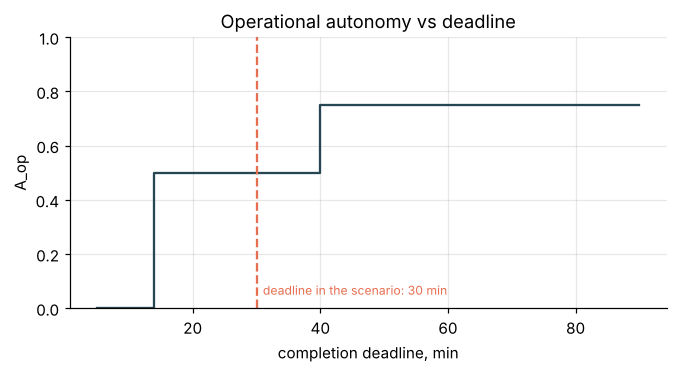

[13.3, 13.3, 40.0, nan]


In [18]:
dur = (ev_df.t_done - ev_df.t_created) / 60          # minutes from creation to completion; NaN = not completed
D = np.arange(5, 91)
A = [(dur <= d).sum() / len(ev_df) for d in D]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.step(D, A, where="post", color=C["base"])
ax.axvline(30, color=C["bad"], ls="--"); ax.text(31, .05, "deadline in the scenario: 30 min", color=C["bad"], fontsize=8)
ax.set_ylim(0, 1); ax.set_xlabel("completion deadline, min"); ax.set_ylabel("A_op")
ax.set_title("Operational autonomy vs deadline"); plt.show()
print(dur.round(1).tolist())

**Comment.** *A*ₒₚ changes in steps: 0 (deadline < 13 min) → 0.5 → 0.75 (deadline ≥ 40 min). The 0.75 ceiling
comes from the operation that was never completed, and no deadline can lift it. If the deadline were chosen
*after* seeing the data, *A*ₒₚ could be tuned at will. That is why deadlines and success criteria are fixed before
measurement (Section 8 of the proposal).

## 9. Link to the article's economic model

According to the article, the investment breaks even if more than **q\* = 35.4 %** of communication-related losses
are avoided (base scenario: three-year NPV 35,895 UAH, payback 17.1 months, P(NPV > 0) = 0.763).
The measured *R*ₗₒₛₛ is the closest field counterpart of *q*. It equals *q* only if the baseline accounting
(stage 1 of the plan) shows that these losses are really caused by communication failures.

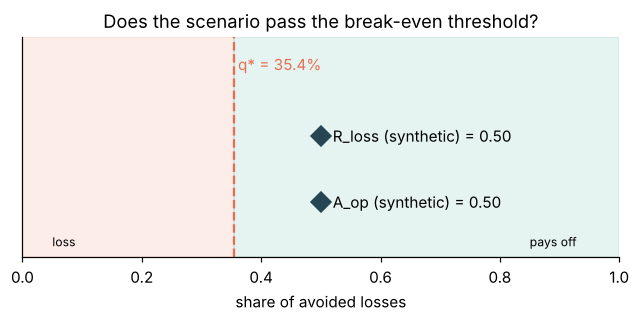

Margin over the threshold: +14.6 pp


In [19]:
Q_STAR = 0.354
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.axvspan(0, Q_STAR, color=C["bad"], alpha=.12); ax.axvspan(Q_STAR, 1, color=C["ok"], alpha=.12)
ax.axvline(Q_STAR, color=C["bad"], ls="--"); ax.text(Q_STAR, .85, f" q* = {Q_STAR:.1%}", color=C["bad"])
for y, (lbl, v) in zip([.55, .25], [("R_loss (synthetic)", R_loss), ("A_op (synthetic)", A_op)]):
    ax.plot(v, y, "D", color=C["base"], ms=9); ax.text(v + .02, y, f"{lbl} = {v:.2f}", va="center")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_yticks([]); ax.grid(False)
ax.set_xlabel("share of avoided losses"); ax.text(.05, .05, "loss", fontsize=8); ax.text(.85, .05, "pays off", fontsize=8)
ax.set_title("Does the scenario pass the break-even threshold?"); plt.show()
print(f"Margin over the threshold: {(R_loss - Q_STAR) * 100:+.1f} pp")

**Comment.** In the synthetic scenario *R*ₗₒₛₛ = 0.5 exceeds *q*\*, but this rests on only 4 operations of equal
value. One operation shifts *R*ₗₒₛₛ by 25 pp, so the threshold is easily crossed in either direction. A conclusion
requires a pilot with dozens of critical operations and a real loss estimate for each.

## 10. Conclusions

1. **The code is reproducible.** The chain "packet log → SQLite → KPIs" yields the same numbers as the archive's
   reference output, and the manual calculations of *η*, *A*ₒₚ, *R*ₗₒₛₛ and AoI match `kpi.py`.
2. **Channel capacity is not the constraint.** The 24-byte frame needs ≈ 2.4 times less airtime than JSON with the
   same content, and *U* = 4.2 % is far from the 25 % limit. The bottlenecks are coverage and power, as in the
   article's model. Relay `airUtilTx` should be watched (1.3 % against a 1 % limit).
3. **Age of information is sensitive to loss bursts.** The formula $\overline{\Delta}=\tfrac{T}{2}\tfrac{1+q}{1-q}$,
   confirmed by Monte Carlo, gives ≈ 6.8 min at 15 % loss, yet a burst of three consecutive losses already produced
   40 min. Dispatchers need the current and maximum age, not the average delivery ratio (`stale_nodes` in `kpi.py`
   only sees the end of the window).
4. **"Delivered" ≠ "done".** With 100 % acceptance only 50 % of events were completed on time (*η* = 0.5).
   This gap, not the radio indicators, determines the economic effect.
5. **Deadlines are fixed in advance.** *A*ₒₚ depends on the deadline in steps (from 0 to 0.75), so a deadline
   chosen after the measurements distorts the result.
6. **The economic conclusion is still conditional.** *R*ₗₒₛₛ = 0.5 > *q*\* = 0.354 holds only on synthetic data
   with 4 operations. An investment decision requires field values of *A*ₒₚ, *η* and the baseline losses *L*.

### Next steps for the pilot
* connect the collector to a real gateway (`collector.py --serial …`) and record firmware and preset in `node_registry`;
* import the plan of critical operations with real `loss_if_failed_uah` before the start;
* record outage windows in `outage` to build the service loss and recovery profile;
* rerun this notebook on the field database: only the database path and the `T0`/`T1` window need to change.